# 02　OFDM：解调

从 `mod_01_OFDM.npz` 读**原始字**，把接收机重跑一遍。本册不碰 PL / DMA。

```
去直流 → 训练相关定位（并判共轭） → 两段训练符号量 CFO → 逐子载波 LS 信道
      → 每个数据符号用导频纠公共相位 → 均衡 → QPSK 判决 → 逐帧 BER / EVM / 余量
```

| 环节 | OFDM 的做法 |
|---|---|
| 同步 | 与已知训练符号 T 做互相关，取第一个过半个峰值的局部峰 |
| 共轭 | 环回把基带取共轭；比较 \|corr(r,T)\| 与 \|corr(r,conj(T))\|，整段取 conj |
| 频偏 | 两个相邻训练符号同位置复相关的相位差，$\Delta f=-\angle z\cdot f_s/(2\pi L)$ |
| 信道 | $H_k=R_k/X_k$，两段训练平均；不插值，数据子载波直接用同一份 H |
| 相位 | 导频处 $R_k/(H_kP_k)$ 的相位均值，每个数据符号单独纠一次 |
| 判决 | QPSK 硬判决，与 `mod_dsp.Const` 的 Gray 映射共用同一套规则 |


## 1　导入与输入文件

In [1]:
import os
import sys

# 库目录：mod_dsp / mod_cases / ofdm_dsp / ofdm_case / 全部 .npz 都在这里
LIB  = "/home/xilinx/modulation"
QPSK = "/home/xilinx/qpsk"        # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "OFDM"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
# 抓包（第 N_TX 册写，第 N_DEMOD / N_VERIFY 册读）与指标（第 N_DEMOD 册写）
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C
import ofdm_dsp as O
import ofdm_case as OC

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

print("ofdm_dsp :", O.__file__)
print("ofdm_case:", OC.__file__)
print("案例     : %s（OFDM，%d 子载波 / %d bit 每帧）"
      % (CASE, len(O.K_USED), O.N_BITS))
print("库目录   :", LIB)
import qpsk_dsp as D

print("qpsk_dsp :", D.__file__)
print("抓包文件 :", CAP_NPZ)


ofdm_dsp : /home/xilinx/modulation/ofdm_dsp.py
ofdm_case: /home/xilinx/modulation/ofdm_case.py
案例     : OFDM（OFDM，106 子载波 / 1024 bit 每帧）
库目录   : /home/xilinx/modulation
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
抓包文件 : /home/xilinx/modulation/mod_01_OFDM.npz


In [2]:
if not os.path.exists(CAP_NPZ):
    raise FileNotFoundError(
        "缺 %s —— 先跑 %02d_%s_tx_rx.ipynb 第 4 节" % (CAP_NPZ, N_TX, CASE))

z = np.load(CAP_NPZ, allow_pickle=False)
print("抓包 %s（%.2f MB）" % (os.path.basename(CAP_NPZ),
                             os.path.getsize(CAP_NPZ) / 1e6))
print("  字 %d，原始长度 %d，突发长 %d 点，字率 %.3f MHz"
      % (len(z["words"]), int(z["n_real"]), int(z["bb_len"]),
         float(z["fs_word"]) / 1e6))
print("  真值比特 %d，帧 %d，N=%d CP=%d"
      % (len(z["bits"]), int(z["frames"]), int(z["n_fft"]), int(z["cp"])))


抓包 mod_01_OFDM.npz（0.44 MB）
  字 176128，原始长度 4194299，突发长 90112 点，字率 256.000 MHz
  真值比特 9216，帧 9，N=1024 CP=128


## 2　解调

`OC.load_and_demod()` 把上面整条流水线跑完。`verbose=True` 会打印活跃区、相关峰个数/间距、
共轭方向与 CFO —— 同步出问题时，先看这几行。


In [3]:
r = OC.load_and_demod(CAP_NPZ, verbose=True)
m, sync = r["metrics"], r["sync"]

print()
print("  共轭方向 %s，CFO %+.1f Hz，训练相关峰 %d 个"
      % ("是" if sync["conjugated"] else "否", sync["cfo"], len(sync["peaks"])))
print("  %-8s %9s %8s %8s %9s"
      % ("帧", "误码", "EVM%", "余量", "CPE/°"))
for q in r["res"]:
    print("  %-8s %4d/%-4d %8.2f %8.3f %+9.1f"
          % (q["tag"], q["err"], q["n"], q["evm"], q["margin"],
             np.degrees(np.mean(q["cpes"]))))
print("  合计 %d/%d 误码，EVM max %.2f%%，余量 min %.3f"
      % (m["err"], m["tot"], m["evm_max"], m["margin_min"]))


  活跃区 [20480, 110592)，相关峰 18 个，首峰 22418，峰间距 [1152 8576 1152 8576 1152 8576]
  共轭方向 是，CFO -10.1 Hz

  共轭方向 是，CFO -10.1 Hz，训练相关峰 18 个
  帧               误码     EVM%       余量     CPE/°
  frame0      0/1024     1.31    0.968      +0.1
  frame1      0/1024     1.38    0.966      -0.1
  frame2      0/1024     1.43    0.959      -0.0
  frame3      0/1024     1.42    0.966      +0.1
  frame4      0/1024     1.52    0.959      -0.1
  frame5      0/1024     1.55    0.962      +0.2
  frame6      0/1024     1.41    0.966      +0.0
  frame7      0/1024     1.24    0.967      -0.0
  frame8      0/1024     1.45    0.965      +0.2
  合计 0/9216 误码，EVM max 1.55%，余量 min 0.959


**应该看到**：

```
  活跃区 […)，相关峰 18 个，首峰 …，峰间距 [1152 1152 … 8576 …]
  共轭方向 是，CFO +… Hz
  帧      误码      EVM%     余量     CPE/°
  frame0    0/1024     2.xx    0.9xx      +x.x
  ...
  合计 0/9216 误码，EVM max ~1.5%，余量 min ~0.96
```

18 个训练符号 = 9 帧 × 2；峰间距在帧内是 1152（4.5 µs），跨帧是 8576（33.5 µs）。
**共轭方向必须是"是"**：本板 DAC 上混频与 ADC 下混频的符号约定相反，接收基带是发送的共轭。
共轭等于频谱左右翻转，如果判错，逐子载波信道估计会把数据子载波与导频对到错误位置，
现象是 BER 约 50%、EVM 约 100%。

**不对怎么查**：

| 现象 | 含义 | 处置 |
|---|---|---|
| `训练符号相关峰没找到` | 环回断 / 突发被裁 / 峰值太小 | 看 01 的活跃区与 rms；重跑 01 |
| 峰间距异常的 1152/8576 | 训练符号被噪声顶掉一个 | 检查环回接触；必要时降低 `probe` 失败重试 |
| 共轭方向判错 | 相关峰太低，两条曲线接近 | 同上；正常信噪比下正常/共轭差 3 倍以上 |
| CFO 上千 Hz | NCO 两侧不同频或采样钟偏差 | 回 00 第 4 节确认两侧 NCO=1000 MHz |
| BER ≈ 50%、EVM ≈ 100% | 共轭未纠正 / 子载波下标错位 | 先确认"共轭方向 是"；再核对 `K % N` 口径 |


## 3　存盘

只存标量指标与逐帧数组，供 `03_OFDM_verify` 出判定表；原始数据仍在抓包 `.npz` 里，
要重算直接重跑本册。


In [4]:
out = {}
for k, v in r["metrics"].items():
    if isinstance(v, (int, float, np.integer, np.floating, bool)):
        out[k] = np.float64(v)
out["case"] = np.array(CASE)
out["evm_f"]    = np.array([q["evm"] for q in r["res"]], np.float64)
out["margin_f"] = np.array([q["margin"] for q in r["res"]], np.float64)
out["err_f"]    = np.array([q["err"] for q in r["res"]], np.int64)

np.savez_compressed(DEM_NPZ, **out)
print("已保存 %s（%.1f KB，%d 个指标）"
      % (DEM_NPZ, os.path.getsize(DEM_NPZ) / 1e3, len(out)))
print("指标：", ", ".join(sorted(k for k in out if k != "case")))


已保存 /home/xilinx/modulation/mod_02_OFDM.npz（2.6 KB，13 个指标）
指标： bb_len, ber, cfo, conjugated, err, err_f, evm_f, evm_max, frames, margin_f, margin_min, tot


## 4　图

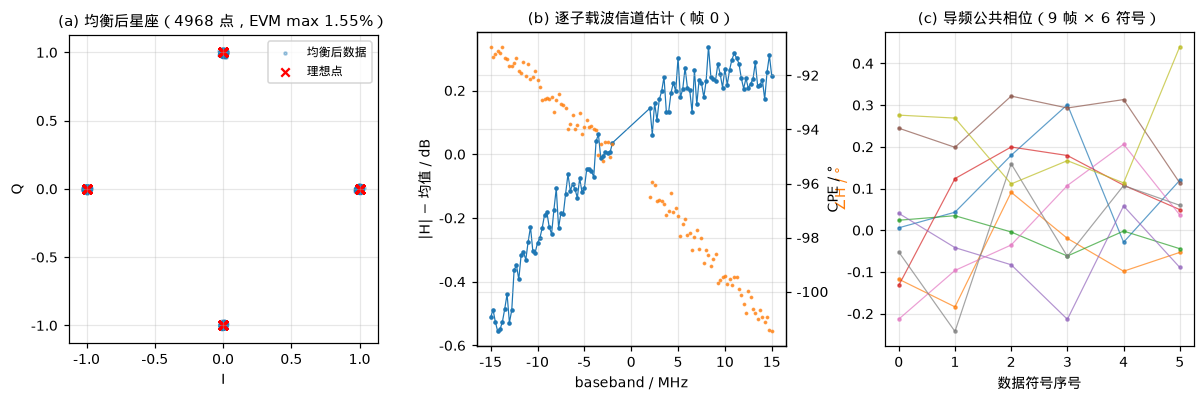

In [5]:
fig = plt.figure(figsize=(13.2, 3.7))
gs = fig.add_gridspec(1, 3, wspace=0.32)

ax = fig.add_subplot(gs[0, 0])
Y = np.concatenate([q["Y"] for q in r["res"]])
ideal = np.concatenate([q["ideal"] for q in r["res"]])
ax.scatter(Y.real, Y.imag, s=4, alpha=0.35, label="均衡后数据")
ax.scatter(ideal.real, ideal.imag, s=30, marker="x", color="r",
           label="理想点")
ax.set_xlabel("I"); ax.set_ylabel("Q"); ax.set_aspect("equal")
ax.set_title("(a) 均衡后星座（%d 点，EVM max %.2f%%）"
             % (len(Y), m["evm_max"]))
ax.legend(loc="upper right")

ax = fig.add_subplot(gs[0, 1])
H = r["res"][0]["H"]
kk = O.K_USED
fq = kk * O.SPACING / 1e6
hdb = 20 * np.log10(np.abs(H[kk % O.N]) + 1e-12)
ax.plot(fq, hdb - np.mean(hdb), ".-", ms=4, lw=0.8)
ax.set_xlabel("baseband / MHz"); ax.set_ylabel("|H| − 均值 / dB")
ax.set_title("(b) 逐子载波信道估计（帧 0）")

ax2 = ax.twinx()
ax2.plot(fq, np.degrees(np.angle(H[kk % O.N])), ".", ms=3, color="C1",
         alpha=0.7)
ax2.set_ylabel("∠H / °", color="C1")

ax = fig.add_subplot(gs[0, 2])
for q in r["res"]:
    ax.plot(np.arange(O.N_SYM), np.degrees(q["cpes"]), ".-", ms=4, lw=0.8,
            alpha=0.7)
ax.set_xlabel("数据符号序号"); ax.set_ylabel("CPE / °")
ax.set_title("(c) 导频公共相位（9 帧 × %d 符号）" % O.N_SYM)
plt.show()


## 5　判读要点

| 图 | 正常形态 | 异常含义 |
|---|---|---|
| (a) 星座 | 四团紧致，EVM 几 % | 四团旋转 → CFO 未校或共轭未纠；弥散 → 削顶/ADC 单通道 |
| (b) \|H\| | ±1~2 dB 的平缓起伏 | 边缘滚降 >3 dB → 占用带太宽，减小 `K_MAX` |
| (b) ∠H | 近似直线（固定时延） | 折线跳变 → 定时误差超过 CP，或训练窗口错位 |
| (c) CPE | 每帧内几度以内 | 逐符号线性增长 → 残余 CFO；跳变 → 导频被噪声/干扰污染 |
